# 05 — gradient boosting (XGBoost)

linear models hit a ceiling fast because house prices aren't linear. XGBoost builds an ensemble of trees and handles non-linearity well.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score, GridSearchCV

from src.train import train_model, cross_val_rmse, save_model
from src.evaluate import evaluate, plot_residuals, plot_feature_importance

sns.set_theme(style='whitegrid')

train = pd.read_csv('../data/processed/train.csv')
test  = pd.read_csv('../data/processed/test.csv')

X_train = train.drop(columns=['price']).values
y_train = train['price'].values
X_test  = test.drop(columns=['price']).values
y_test  = test['price'].values

feature_names = train.drop(columns=['price']).columns.tolist()
print(f"features: {len(feature_names)}")

features: 11


## baseline XGBoost — default params

In [2]:
xgb_base = train_model(X_train, y_train, model_type='xgboost')
pred_xgb_base = xgb_base.predict(X_test)

evaluate(y_test, pred_xgb_base, label='XGBoost (default)')
cv_rmse = cross_val_rmse(xgb_base, X_train, y_train)
print(f"5-fold CV RMSE: {cv_rmse:.4f}")

XGBoost (default) — RMSE: 0.4666  R²: 0.8339
5-fold CV RMSE: 0.4755


## hyperparameter tuning

key XGBoost params to tune:
- `n_estimators` — number of trees
- `max_depth` — how deep each tree goes (higher = more complex)
- `learning_rate` — how much each tree contributes
- `subsample` — fraction of training rows used per tree (prevents overfitting)

In [3]:
param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [3, 4, 6],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.8, 1.0],
}

# warning: this takes a few minutes
xgb = XGBRegressor(random_state=42, verbosity=0)
grid = GridSearchCV(
    xgb,
    param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid.fit(X_train, y_train)

print("\nbest params:", grid.best_params_)
print(f"best CV RMSE: {np.sqrt(-grid.best_score_):.4f}")

Fitting 5 folds for each of 54 candidates, totalling 270 fits

best params: {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 500, 'subsample': 0.8}
best CV RMSE: 0.4550


In [4]:
# train final model with best params
best_params = grid.best_params_
xgb_tuned = train_model(X_train, y_train, model_type='xgboost', **best_params)
pred_xgb_tuned = xgb_tuned.predict(X_test)

result_xgb = evaluate(y_test, pred_xgb_tuned, label='XGBoost (tuned)')

XGBoost (tuned) — RMSE: 0.4473  R²: 0.8473


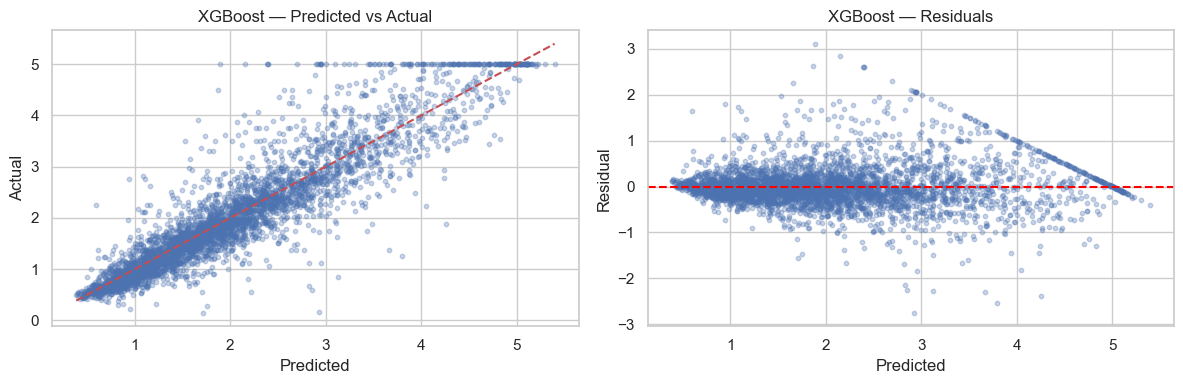

In [5]:
plot_residuals(y_test, pred_xgb_tuned, label='XGBoost')

## feature importance

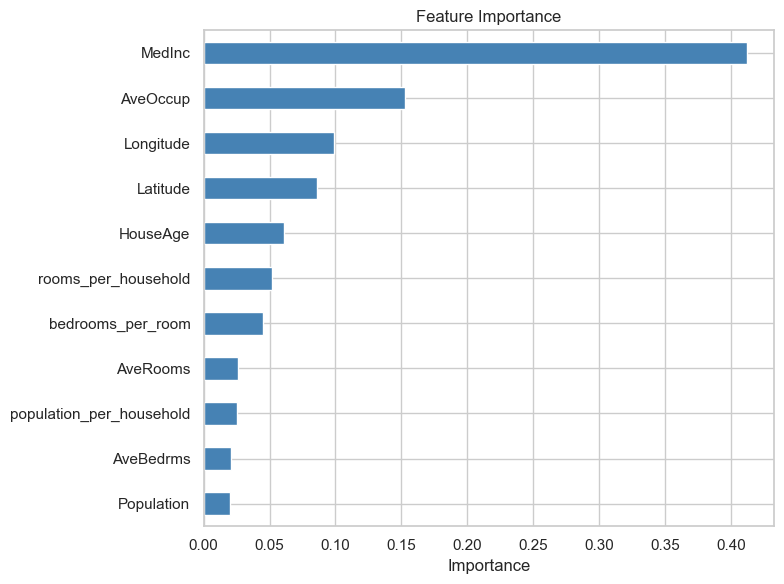

In [6]:
plot_feature_importance(xgb_tuned, feature_names)

## learning curve — are we overfitting?

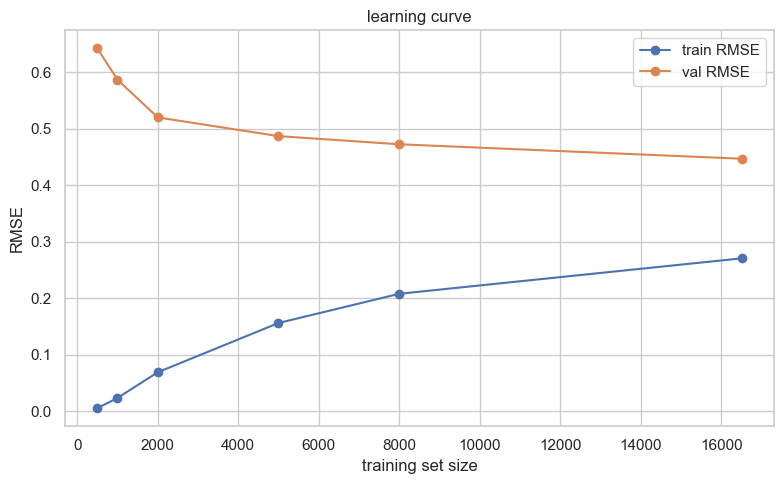

In [7]:
train_sizes = [500, 1000, 2000, 5000, 8000, len(X_train)]
train_rmses, val_rmses = [], []

for n in train_sizes:
    xgb_tmp = XGBRegressor(**best_params, random_state=42, verbosity=0)
    xgb_tmp.fit(X_train[:n], y_train[:n])

    train_pred = xgb_tmp.predict(X_train[:n])
    val_pred   = xgb_tmp.predict(X_test)

    train_rmses.append(np.sqrt(np.mean((y_train[:n] - train_pred)**2)))
    val_rmses.append(np.sqrt(np.mean((y_test - val_pred)**2)))

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_rmses, label='train RMSE', marker='o')
plt.plot(train_sizes, val_rmses,   label='val RMSE',   marker='o')
plt.xlabel('training set size')
plt.ylabel('RMSE')
plt.title('learning curve')
plt.legend()
plt.tight_layout()
plt.savefig('../plots/learning_curve.png', dpi=120)
plt.show()

In [8]:
save_model(xgb_tuned, '../models/xgboost_tuned.pkl')

saved → ../models/xgboost_tuned.pkl
